In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import os
import sys
import glob
import uproot

def gaus(x, A, mean, std):
    return A * np.exp(-1 * (x - mean)**2 / 2*(std))

def sigmoid(x, A, mean, width):
    return (A / (1 + np.exp(-1 * width * (x - mean))))

proc_F_AC_LGAD_40um_strip_10db_attenuation_LaserTuneScan_NEv1000_BV115000mV_Laser100.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_AC_LGAD_40um_strip_10db_attenuation_LaserTuneScan_NEv1000_BV115000mV_Laser80.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_AC_LGAD_40um_strip_10db_attenuation_LaserTuneScan_NEv1000_BV115000mV_Laser60.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_AC_LGAD_40um_strip_10db_attenuation_LaserTuneScan_NEv1000_BV115000mV_Laser40.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_AC_LGAD_40um_strip_10db_attenuation_LaserTuneScan_NEv1000_BV115000mV_Laser20.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_AC_LGAD_40um_strip_10db_attenuation_LaserTuneScan_NEv1000_BV115000mV_Laser0.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root


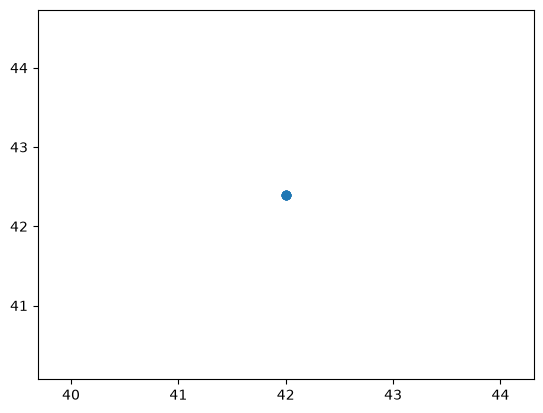

In [7]:
path = "../../Processed_data/"
# path = "../../ZAxisScan/"
# files = glob.glob(f"{path}proc_F_AC_LGAD_40um_strip_NEv*000_BV115000mV_Laser20pc_Temp16C_Zpos*_Xpos*00000.root")
files = glob.glob(f"{path}proc_F_AC_LGAD_40um_strip_10db_attenuation_LaserTuneScan_NEv1000_BV115000mV_Laser*pc_Temp16C_Zpos*_Xpos*_Ypos*00000.root")

# files = glob.glob(f"{path}F*--AC_LGAD_40um_strip_NEv*000_BV115000mV_Laser20pc_Temp16C_Zpos*_Xpos*00000.trc")

Z_range = [] # np.linspace(50.0, 50.8, 11)
X_range = [] # np.linspace(41.4, 41.7, 21)
Y_range = []
laser_tune = []

map_plot_x = []
map_plot_y = []
map_plot_z = []

for file in files:
    filename = file.split(path)[1]
    print(filename)
    x_pos = float(filename.split("Xpos")[1].split("_")[0])
    y_pos = float(filename.split("Ypos")[1].split("00000.root")[0])
    z_pos = float(filename.split("Zpos")[1].split("_")[0])
    lt = float(filename.split("mV_Laser")[1].split("pc_")[0])
    map_plot_x.append(x_pos)
    map_plot_y.append(y_pos)
    map_plot_z.append(z_pos)
    laser_tune.append(lt)
    X_range.append(x_pos)
    Y_range.append(y_pos)
    Z_range.append(z_pos)

Z_range = np.unique(Z_range)
X_range = np.unique(X_range)
Y_range = np.unique(Y_range)

# map_plot_x = np.sort(map_plot_x)
# map_plot_z = np.sort(map_plot_z)

plt.scatter(map_plot_x, map_plot_z)
plt.show()

fields = [
    'i_evt',
    # 'channel',
    # 'time',
    # 'baseline',
    'baseline_RMS',
    'noise',
    'amp',
    # 't_peak',
    'integral',
    # 'intfull',
    # 'risetime',
    # 'decaytime',
    # 'LP2_5',
    # 'LP2_10',
    # 'LP2_15',
    # 'LP2_20',
    # 'LP2_25',
    # 'LP2_30',
    # 'LP2_35',
    # 'LP2_40',
    # 'LP2_45',
    'LP2_50',
    # 'LP2_55',
    # 'LP2_60',
    # 'LP2_65',
    # 'LP2_70',
    # 'LP2_75',
    # 'LP2_80',
    # 'LP2_85',
    # 'LP2_90',
    # 'LP2_95',
    # 'LP2_100',
    # 'LP2_10mV',
    # 'LP2_20mV',
    # 'LP2_30mV',
    # 'LP2_50mV',
    # 'LP2_70mV',
    # 'LP2_90mV',
    # 'LP2_100mV',
    # 'LP2_120mV',
    # 'LP2_140mV',
    # 'LP2_160mV',
    # 'LP2_180mV',
    # 'LP2_200mV',
    # 'linear_RE_5',
    # 'linear_RE_10',
    # 'linear_RE_15',
    # 'linear_RE_20',
    # 'linear_RE_25',
    # 'linear_RE_30',
    # 'linear_RE_35',
    # 'linear_RE_40',
    # 'linear_RE_45',
    # 'linear_RE_50',
    # 'linear_RE_55',
    # 'linear_RE_60',
    # 'linear_RE_65',
    # 'linear_RE_70',
    # 'linear_RE_75',
    # 'linear_RE_80',
    # 'linear_RE_85',
    # 'linear_RE_90',
    # 'linear_RE_95',
    # 'linear_RE_100',
    # 'linear_RE__10mV',
    # 'linear_RE__20mV',
    # 'linear_RE__30mV',
    # 'linear_RE__50mV',
    # 'linear_RE__70mV',
    # 'linear_RE__90mV',
    # 'linear_RE__100mV',
    # 'linear_RE__120mV',
    # 'linear_RE__140mV',
    # 'linear_RE__160mV',
    # 'linear_RE__180mV',
    # 'linear_RE__200mV'
]
    

In [9]:
integral = {}
amp = {}
t_peak = {}
risetime = {}
timestamps = {}
baseline_RMS = {}
risetime = {}
channel = {}
time = {}

for f_i, f in enumerate(files):
    pulse = uproot.open(f)["pulse"].arrays(fields)
    l = f"pos_{map_plot_z[f_i]}_{map_plot_x[f_i]}_{map_plot_y[f_i]}_{laser_tune[f_i]}"
    # channel[l] = pulse["channel"]
    # time[l] = pulse["time"]
    integral[l] = pulse["integral"]
    # risetime[l] = pulse["risetime"]
    amp[l] = pulse["amp"]
    baseline_RMS[l] = pulse["baseline_RMS"]
    timestamps[l] = pulse["LP2_50"]
    del pulse

print(amp.keys())

dict_keys(['pos_42.4_42.0_106.0_100.0', 'pos_42.4_42.0_106.0_80.0', 'pos_42.4_42.0_106.0_60.0', 'pos_42.4_42.0_106.0_40.0', 'pos_42.4_42.0_106.0_20.0', 'pos_42.4_42.0_106.0_0.0'])


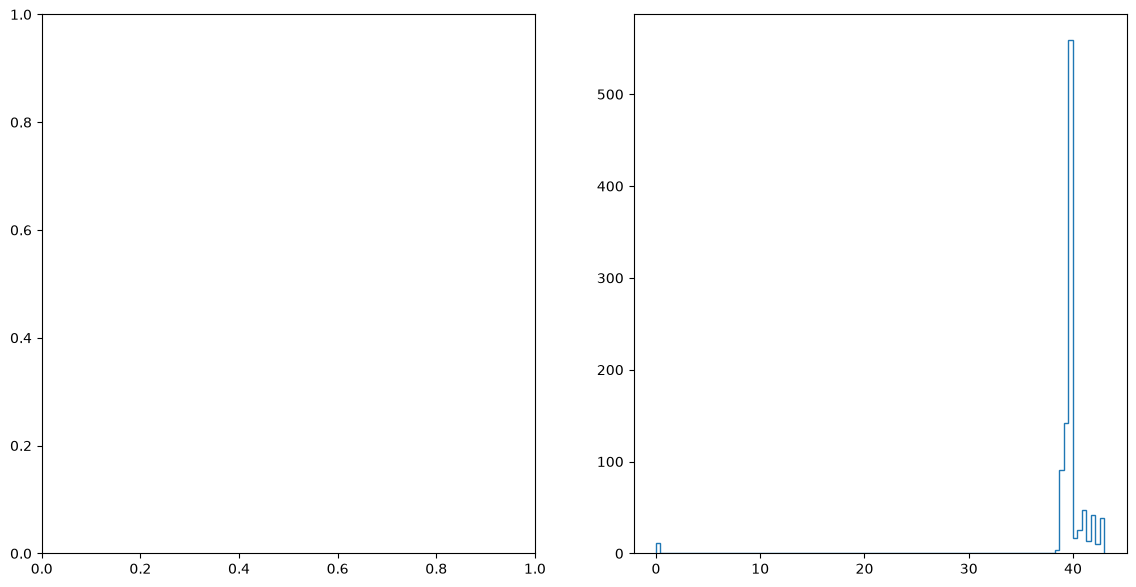

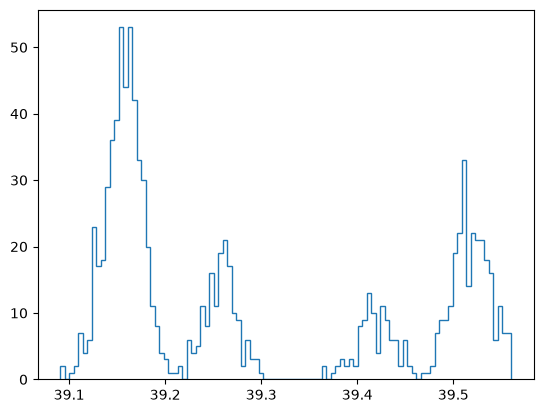

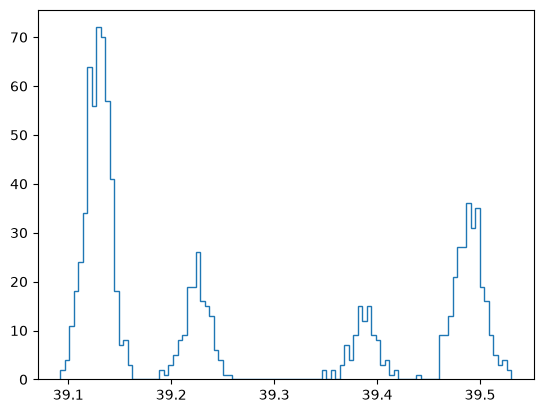

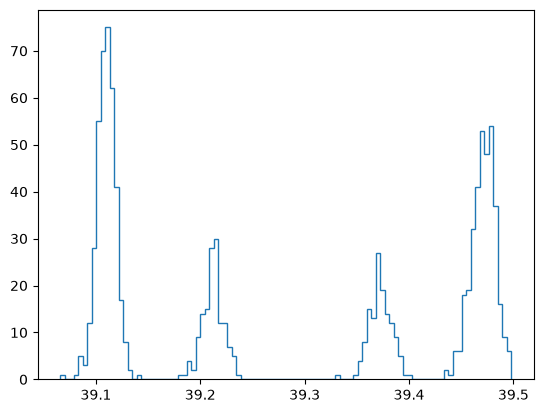

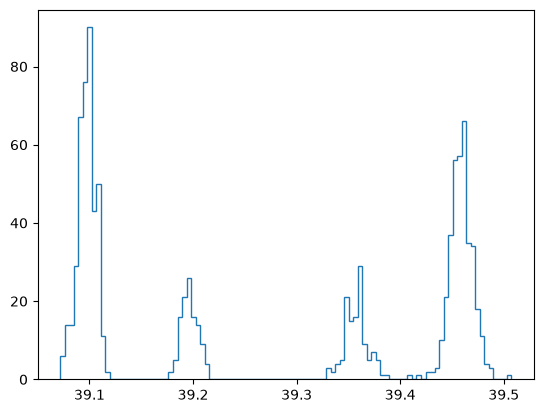

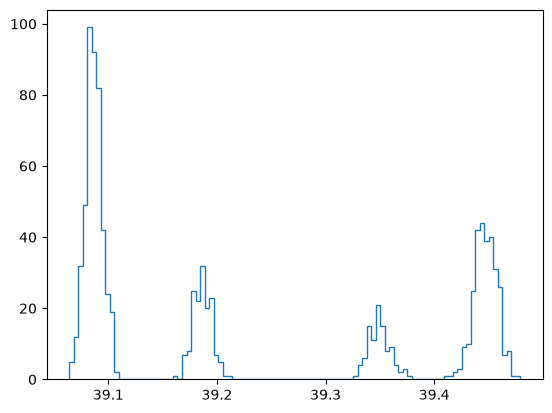

[np.float64(4.855055931925774), np.float64(25.463753385543825), np.float64(43.887889430999756), np.float64(59.15286394119263), np.float64(72.03260692977905), np.float64(78.8588267211914)]
6


/tmp/ipykernel_1056450/4290223296.py:43: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


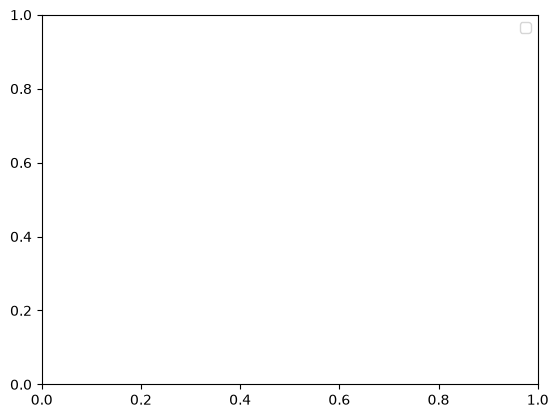

In [25]:
cols = 2
rows = 1
size = 7
channel = 5

fig, ax = plt.subplots(rows, cols, figsize = (size*cols, size*rows))
mean_amps = []
n_events = []
for lt_i, lt in enumerate(laser_tune):
    for z_i, z in enumerate(Z_range):
        for x_i, x in enumerate(X_range):
            for y_i, y in enumerate(Y_range):
                l = f"pos_{z}_{x}_{y}_{lt}"
                dt = timestamps[l][:,channel] - timestamps[l][:,7]
                try:
                    mean_amps.append(np.mean(amp[l][:,channel]))
                    n_events.append(np.mean(dt))
                    plt.hist(dt, bins = 100, histtype = "step")
                    plt.show()
                except:
                    mean_amps.append(0)
                    n_events.append(0)
print(mean_amps)

sorting = np.argsort(laser_tune)

mean_amps = np.array(mean_amps)
n_events = np.array(n_events)

# params = curve_fit(gaus, X_range[mask], mean_amps[mask], p0 = (np.max(mean_amps[mask]), np.mean(X_range[mask]), 10))

ax[0].plot(laser_tune, mean_amps, label = f"Z position: {z}", marker = "o")
ax[0].set_xlabel("X position [mm]")
ax[0].set_ylabel("Mean amplitude")

mask = (mean_amps != 0)
print(np.sum(mask))

ax[1].plot(laser_tune, n_events, label = f"Z position: {z}")
ax[1].set_xlabel("X position [mm]")
ax[1].set_ylabel("Number of events")

plt.legend()
plt.show()